# CNN Feature Visualization, Parameter Audit & Critical Analysis
**Deep Learning & Computer Vision — Practical Laboratory Assignment**

| | |
|---|---|
| **Student Name** | Dua e Zainab |
| **Registration / Roll No.** | FA34-BAI-027 |
| **Course / Section** | Deep Learning & Computer Vision / ________ |
| **Submission Date** | 26 November 2026 |

**Notebook map**

| Part | Content |
|---|---|
| 0 | Setup + image loading |
| I | 5 custom 3×3 kernels → Stage A (Conv), B (ReLU), C (MaxPool), D (AvgPool) → **5 × 4 grid** |
| II | Model A vs Model B: manual parameter audit vs `model.summary()` |
| III | Evidence + answers to Questions 1–5 |

> Run **Kernel → Restart & Run All**. Every number quoted in the answers is computed by code in this notebook.

## Part 0 — Setup

In [1]:
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
from numpy.lib.stride_tricks import sliding_window_view

np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print("NumPy", np.__version__, "| OpenCV", cv2.__version__)

NumPy 2.4.6 | OpenCV 5.0.0


'building.jpg' not found -> using synthetic facade (256, 256)


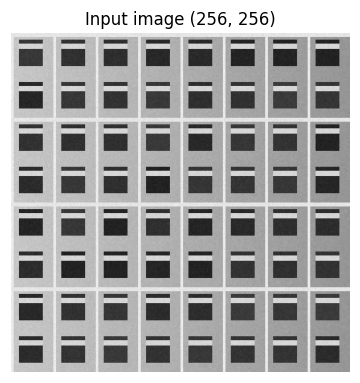

In [2]:
IMAGE_PATH = "building.jpg"     # <-- change to your own image file
SIZE = 256                      # working resolution (even number so 2x2 pooling divides cleanly)

def synthetic_facade(n=256, seed=0):
    """High-contrast facade: grid of dark windows, bright frames, vertical mullions, light gradient + noise."""
    rng = np.random.default_rng(seed)
    img = np.full((n, n), 175.0)
    img += np.linspace(25, -25, n)[None, :]                 # horizontal lighting gradient
    step = n // 8
    for r in range(8):
        for c in range(8):
            y0, x0 = r * step + 5, c * step + 6
            img[y0:y0 + step - 12, x0:x0 + step - 14] = 35 + rng.integers(0, 25)   # dark window
            img[y0 + 3:y0 + 7, x0:x0 + step - 14] = 215                            # bright sill
    for c in range(0, n, step):
        img[:, c:c + 2] = 235                                                      # vertical mullions
    for r in range(0, n, step * 2):
        img[r:r + 3, :] = 230                                                      # horizontal floor slabs
    img += rng.normal(0, 3, img.shape)
    return np.clip(img, 0, 255).astype(np.uint8)

if os.path.exists(IMAGE_PATH):
    gray = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
    gray = cv2.resize(gray, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    print(f"Loaded '{IMAGE_PATH}' ->", gray.shape)
else:
    gray = synthetic_facade(SIZE)
    print(f"'{IMAGE_PATH}' not found -> using synthetic facade", gray.shape)

img = gray.astype(np.float32) / 255.0        # normalise to [0, 1]
plt.figure(figsize=(4, 4)); plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.title(f"Input image {img.shape}"); plt.axis("off"); plt.show()

## Part I — Filter Pipeline Implementation & Visualization

### Step 1: Five custom 3×3 kernels
**Naming note (read before the viva).** A kernel's name can describe the *gradient direction* or the *edge orientation it detects*, and the handout mixes them. Here each kernel is named by the **edges it responds to**:
* **Horizontal Edge Detector** = Sobel kernel with `-1 -2 -1` in the top row (responds to horizontal edges, i.e. intensity change along *y*; often called Sobel-Y / Gy).
* **Vertical Edge Detector** = Sobel kernel with `-1` in the left column (responds to vertical edges, i.e. intensity change along *x*; often called Sobel-X / Gx).

Both are the two Sobel filters; only the labelling convention differs. CNN layers actually compute **cross-correlation** (no kernel flip), and so does the code below.

In [3]:
kernels = {
    "Horizontal Edge (Sobel)": np.array([[-1, -2, -1],
                                         [ 0,  0,  0],
                                         [ 1,  2,  1]], dtype=np.float32),
    "Vertical Edge (Sobel)":   np.array([[-1, 0, 1],
                                         [-2, 0, 2],
                                         [-1, 0, 1]], dtype=np.float32),
    "Sharpen":                 np.array([[ 0, -1,  0],
                                         [-1,  5, -1],
                                         [ 0, -1,  0]], dtype=np.float32),
    "Gaussian Blur":           np.array([[1, 2, 1],
                                         [2, 4, 2],
                                         [1, 2, 1]], dtype=np.float32) / 16.0,
    "Emboss":                  np.array([[-2, -1, 0],
                                         [-1,  1, 1],
                                         [ 0,  1, 2]], dtype=np.float32),
}
for name, k in kernels.items():
    print(f"{name:26s} sum of weights = {k.sum():+.2f}\n{k}\n")

Horizontal Edge (Sobel)    sum of weights = +0.00
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]

Vertical Edge (Sobel)      sum of weights = +0.00
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Sharpen                    sum of weights = +1.00
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]

Gaussian Blur              sum of weights = +1.00
[[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]

Emboss                     sum of weights = +1.00
[[-2. -1.  0.]
 [-1.  1.  1.]
 [ 0.  1.  2.]]



### Step 2: Layer operations (written from scratch with NumPy)
* **Convolution** — 3×3, stride 1, *same* output size (reflect padding), no bias.
* **ReLU** — `max(0, x)`
* **Max / Average Pooling** — 2×2 window, stride 2 (output is H/2 × W/2).

In [4]:
def conv2d(x, k):
    """3x3 'same' cross-correlation (what a CNN Conv layer computes), stride 1."""
    p = k.shape[0] // 2
    xp = np.pad(x, p, mode="reflect")
    win = sliding_window_view(xp, k.shape)          # (H, W, 3, 3)
    return np.einsum("hwij,ij->hw", win, k)

def relu(x):            return np.maximum(0.0, x)
def leaky_relu(x, a=0.1): return np.where(x > 0, x, a * x)
def sigmoid(x):         return 1.0 / (1.0 + np.exp(-x))

def pool2x2(x, mode="max"):
    """2x2 pooling, stride 2 (non-overlapping)."""
    H, W = x.shape
    blocks = x[:H - H % 2, :W - W % 2].reshape(H // 2, 2, W // 2, 2)
    return blocks.max(axis=(1, 3)) if mode == "max" else blocks.mean(axis=(1, 3))

# sanity check against OpenCV (cv2.filter2D is also cross-correlation)
test = cv2.filter2D(img, -1, kernels["Vertical Edge (Sobel)"], borderType=cv2.BORDER_REFLECT_101)
assert np.allclose(test, conv2d(img, kernels["Vertical Edge (Sobel)"]), atol=1e-5)
print("conv2d matches cv2.filter2D  ✔")

conv2d matches cv2.filter2D  ✔


### Step 3: Run all five filters and record the four stages (A, B, C, D)

In [5]:
stages = {}
for name, k in kernels.items():
    A = conv2d(img, k)                 # Stage A: raw convolution
    B = relu(A)                        # Stage B: post-ReLU
    Cm = pool2x2(B, "max")             # Stage C: max pooling 2x2/2
    D = pool2x2(B, "avg")              # Stage D: average pooling 2x2/2
    stages[name] = dict(A=A, B=B, C=Cm, D=D)

rows = []
for name, s in stages.items():
    rows.append({"Filter": name,
                 "A shape": s["A"].shape, "B shape": s["B"].shape,
                 "C shape": s["C"].shape, "D shape": s["D"].shape,
                 "A min": s["A"].min(), "A max": s["A"].max(),
                 "% negative in A": 100 * (s["A"] < 0).mean(),
                 "% exact-zero in B": 100 * (s["B"] == 0).mean()})
pd.DataFrame(rows).round(3)

,Filter,A shape,B shape,C shape,D shape,A min,A max,% negative in A,% exact-zero in B
0,Horizontal Edge (Sobel),"(256, 256)","(256, 256)","(128, 128)","(128, 128)",-2.922,2.914,48.535,51.648
1,Vertical Edge (Sobel),"(256, 256)","(256, 256)","(128, 128)","(128, 128)",-2.631,2.525,51.009,54.739
2,Sharpen,"(256, 256)","(256, 256)","(128, 128)","(128, 128)",-1.290,1.929,9.464,9.464
3,Gaussian Blur,"(256, 256)","(256, 256)","(128, 128)","(128, 128)",0.120,0.933,0.000,0.000
4,Emboss,"(256, 256)","(256, 256)","(128, 128)","(128, 128)",-2.467,3.098,12.076,12.112


### Step 4: Unified **5 × 4** visualization grid
Rows = 5 filters, columns = Stages A–D.
* **Stage A** uses a diverging colormap, symmetric around 0 (blue = negative, red = positive) so negative values are visible.
* **Stages B, C, D** share *one* grey intensity scale per row (`0 … max of Stage B`), so brightness is directly comparable across ReLU → MaxPool → AvgPool. Black = 0.

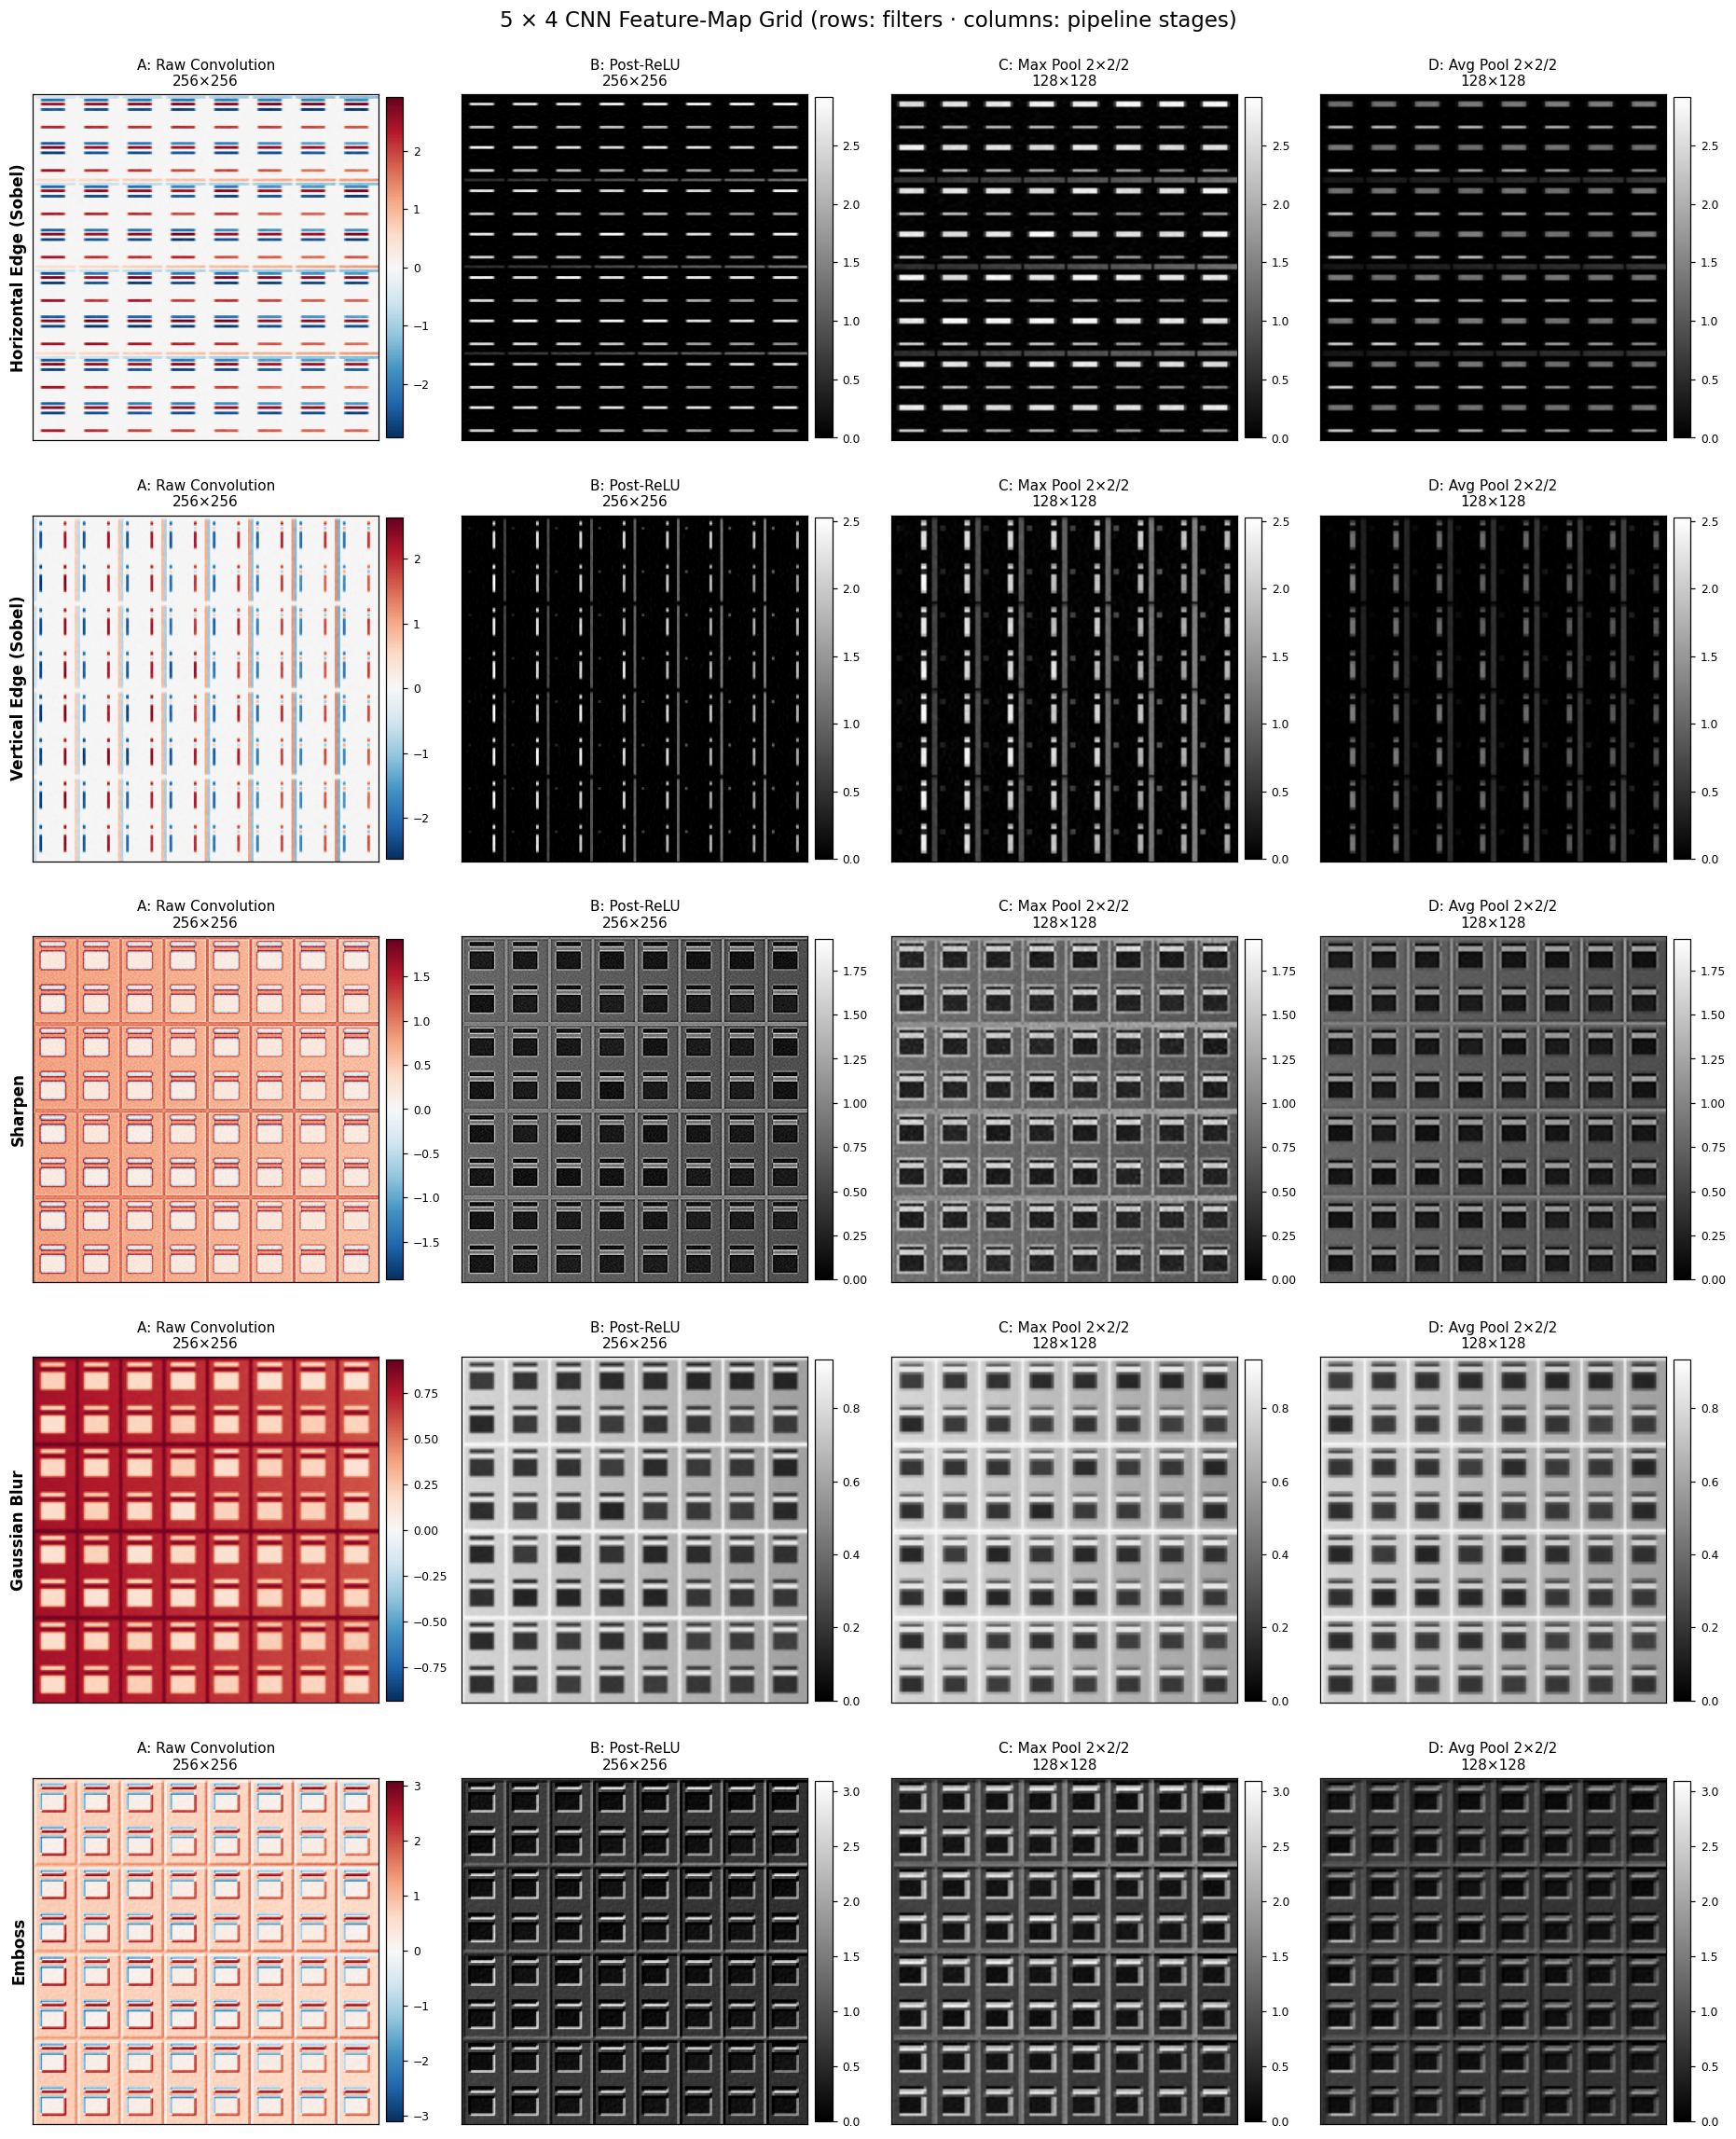

In [6]:
col_titles = ["A: Raw Convolution", "B: Post-ReLU", "C: Max Pool 2×2/2", "D: Avg Pool 2×2/2"]
fig, axes = plt.subplots(5, 4, figsize=(17, 21))
for r, (name, s) in enumerate(stages.items()):
    m = np.abs(s["A"]).max()
    vmax_pos = s["B"].max() if s["B"].max() > 0 else 1.0
    for c, key in enumerate("ABCD"):
        ax = axes[r, c]
        if key == "A":
            im = ax.imshow(s[key], cmap="RdBu_r", vmin=-m, vmax=m)
        else:
            im = ax.imshow(s[key], cmap="gray", vmin=0, vmax=vmax_pos)
        ax.set_title(f"{col_titles[c]}\n{s[key].shape[0]}×{s[key].shape[1]}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(name, fontsize=11, fontweight="bold")
        cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02); cb.ax.tick_params(labelsize=8)
fig.suptitle("5 × 4 CNN Feature-Map Grid (rows: filters · columns: pipeline stages)", fontsize=15, y=0.995)
plt.tight_layout()
plt.savefig("cnn_feature_grid_5x4.png", dpi=150, bbox_inches="tight")
plt.show()

## Part II — Architectural Comparison & Parameter Audit

Both models: input `32×32×3` → **Conv1 (5 filters)** → ReLU → Pool(2×2, s2) → **Conv2 (10 filters)** → ReLU → Pool(2×2, s2) → **Global Average Pooling** → **Dense(10)**.

| Model | Kernel | Pooling |
|---|---|---|
| A (Standard) | 3×3 | Max |
| B (Large Kernel) | 5×5 | Average |

Formulas (pooling, ReLU and GAP have **0** parameters):
* Conv: `(Kh × Kw × Cin + 1) × Cout`
* Dense: `(Nin + 1) × Nout`

### Step 1: Manual calculation (do this *before* `model.summary()`)

In [7]:
def conv_params(k, cin, cout):  return (k * k * cin + 1) * cout
def dense_params(nin, nout):    return (nin + 1) * nout

def manual_audit(k, label):
    c1 = conv_params(k, 3, 5)
    c2 = conv_params(k, 5, 10)
    fc = dense_params(10, 10)           # GAP outputs 10 numbers (one per Conv2 filter)
    print(f"{label}  (kernel {k}x{k})")
    print(f"  Conv1 : ({k}x{k}x3 + 1) x 5   = ({k*k*3}+1) x 5   = {c1}")
    print(f"  Conv2 : ({k}x{k}x5 + 1) x 10  = ({k*k*5}+1) x 10  = {c2}")
    print(f"  Dense : (10 + 1) x 10         = {fc}")
    print(f"  Pool / ReLU / GAP             = 0")
    print(f"  TOTAL                         = {c1} + {c2} + {fc} = {c1+c2+fc}\n")
    return c1 + c2 + fc

manual_A = manual_audit(3, "Model A")
manual_B = manual_audit(5, "Model B")

Model A  (kernel 3x3)
  Conv1 : (3x3x3 + 1) x 5   = (27+1) x 5   = 140
  Conv2 : (3x3x5 + 1) x 10  = (45+1) x 10  = 460
  Dense : (10 + 1) x 10         = 110
  Pool / ReLU / GAP             = 0
  TOTAL                         = 140 + 460 + 110 = 710

Model B  (kernel 5x5)
  Conv1 : (5x5x3 + 1) x 5   = (75+1) x 5   = 380
  Conv2 : (5x5x5 + 1) x 10  = (125+1) x 10  = 1260
  Dense : (10 + 1) x 10         = 110
  Pool / ReLU / GAP             = 0
  TOTAL                         = 380 + 1260 + 110 = 1750



### Step 2: Build both models in Keras and read the framework's count

In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models
tf.random.set_seed(42)

def build_model(k, pooling, name):
    Pool = layers.MaxPooling2D if pooling == "max" else layers.AveragePooling2D
    return models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(5,  (k, k), padding="same", activation="relu", name="conv1"),
        Pool((2, 2), strides=2, name="pool1"),
        layers.Conv2D(10, (k, k), padding="same", activation="relu", name="conv2"),
        Pool((2, 2), strides=2, name="pool2"),
        layers.GlobalAveragePooling2D(name="gap"),
        layers.Dense(10, activation="softmax", name="dense_out"),
    ], name=name)

model_A = build_model(3, "max", "Model_A_Standard")
model_B = build_model(5, "avg", "Model_B_LargeKernel")
model_A.summary()
model_B.summary()

Model: "Model_A_Standard"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_out (Dense)               │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

Model: "Model_B_LargeKernel"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (AveragePooling2D)        │ (None, 16, 16, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (AveragePooling2D)        │ (None, 8, 8, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_out (Dense)               │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)

### Step 3: Completed audit table

In [9]:
audit = pd.DataFrame([
    {"Model Configuration": "Model A (Standard)",    "Conv Architecture": "Conv1: 5 filters, Conv2: 10 filters",
     "Kernel Size": "3 × 3", "Pooling Type": "Max (2×2, s2)", "Manual Count": manual_A, "Code Output": model_A.count_params()},
    {"Model Configuration": "Model B (Large Kernel)", "Conv Architecture": "Conv1: 5 filters, Conv2: 10 filters",
     "Kernel Size": "5 × 5", "Pooling Type": "Avg (2×2, s2)", "Manual Count": manual_B, "Code Output": model_B.count_params()},
])
audit["Match?"] = np.where(audit["Manual Count"] == audit["Code Output"], "✔ yes", "✘ NO")
display(audit)
assert manual_A == model_A.count_params() and manual_B == model_B.count_params()

print("Per-layer shapes (Model A / B share the same spatial sizes because padding='same'):")
for l in model_A.layers:
    print(f"  {l.name:10s} -> {l.output.shape}   params = {l.count_params()}")

,Model Configuration,Conv Architecture,Kernel Size,Pooling Type,Manual Count,Code Output,Match?
0,Model A (Standard),"Conv1: 5 filters, Conv2: 10 filters",3 × 3,"Max (2×2, s2)",710,710,✔ yes
1,Model B (Large Kernel),"Conv1: 5 filters, Conv2: 10 filters",5 × 5,"Avg (2×2, s2)",1750,1750,✔ yes


Per-layer shapes (Model A / B share the same spatial sizes because padding='same'):
  conv1      -> (None, 32, 32, 5)   params = 140
  pool1      -> (None, 16, 16, 5)   params = 0
  conv2      -> (None, 16, 16, 10)   params = 460
  pool2      -> (None, 8, 8, 10)   params = 0
  gap        -> (None, 10)   params = 0
  dense_out  -> (None, 10)   params = 110


## Part III — Critical Thinking & Viva Defense

For each question: first the **evidence cell** (code that measures your own feature maps), then the **written answer**.

### Question 1 — The ReLU "Blackout" Effect & Activation Alternatives
**Evidence:** where do negative values appear in the Horizontal/Vertical edge rows, and what do Leaky-ReLU / Sigmoid do instead?

In [10]:
H_name, V_name = "Horizontal Edge (Sobel)", "Vertical Edge (Sobel)"
for nm in (H_name, V_name):
    A, B = stages[nm]["A"], stages[nm]["B"]
    neg, zero_flat = (A < 0), (A == 0)
    print(f"{nm}")
    print(f"   pixels < 0 in Stage A (killed by ReLU) : {100*neg.mean():5.1f} %")
    print(f"   pixels == 0 in Stage A (flat regions)   : {100*zero_flat.mean():5.1f} %")
    print(f"   pixels == 0 in Stage B (all black)      : {100*(B==0).mean():5.1f} %")
    print(f"   most negative / most positive response  : {A.min():+.2f} / {A.max():+.2f}\n")

# Direction test on a single step edge: dark -> bright going DOWN, and going RIGHT
step_down  = np.vstack([np.zeros((4, 8)), np.ones((4, 8))]).astype(np.float32)   # dark above, bright below
step_right = step_down.T.copy()                                                  # dark left, bright right
kH, kV = kernels[H_name], kernels[V_name]
print("Horizontal kernel on [dark above / bright below] edge  -> response at edge row:",
      conv2d(step_down, kH)[3:5, 4])
print("Horizontal kernel on [bright above / dark below] edge  -> response at edge row:",
      conv2d(1 - step_down, kH)[3:5, 4])
print("Vertical   kernel on [dark left / bright right] edge   -> response at edge col:",
      conv2d(step_right, kV)[4, 3:5])
print("Vertical   kernel on [bright left / dark right] edge   -> response at edge col:",
      conv2d(1 - step_right, kV)[4, 3:5])

Horizontal Edge (Sobel)
   pixels < 0 in Stage A (killed by ReLU) :  48.5 %
   pixels == 0 in Stage A (flat regions)   :   3.1 %
   pixels == 0 in Stage B (all black)      :  51.6 %
   most negative / most positive response  : -2.92 / +2.91

Vertical Edge (Sobel)
   pixels < 0 in Stage A (killed by ReLU) :  51.0 %
   pixels == 0 in Stage A (flat regions)   :   3.7 %
   pixels == 0 in Stage B (all black)      :  54.7 %
   most negative / most positive response  : -2.63 / +2.53

Horizontal kernel on [dark above / bright below] edge  -> response at edge row: [4. 4.]
Horizontal kernel on [bright above / dark below] edge  -> response at edge row: [-4. -4.]
Vertical   kernel on [dark left / bright right] edge   -> response at edge col: [4. 4.]
Vertical   kernel on [bright left / dark right] edge   -> response at edge col: [-4. -4.]


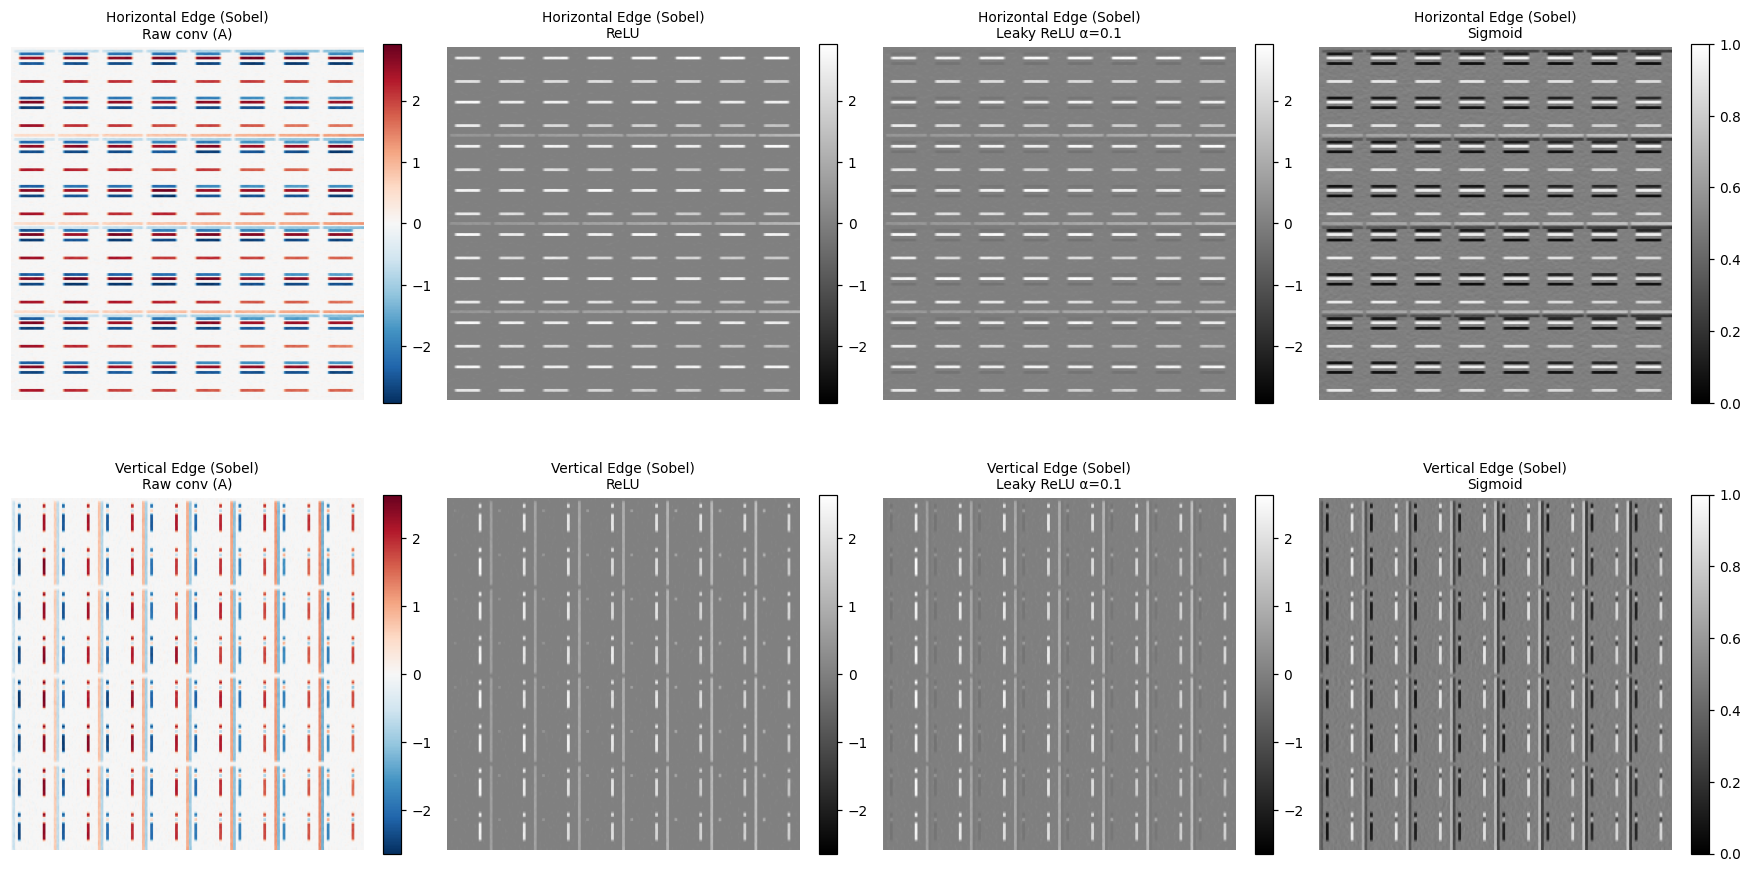

Sigmoid of a flat (0) response = 0.50  -> flat regions become mid-grey, not black
Leaky ReLU keeps negatives at 10% size: min = -0.292 (ReLU min = +0.000)


In [11]:
# Compare activations on the two edge rows: Raw | ReLU | Leaky ReLU (a=0.1) | Sigmoid
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for r, nm in enumerate((H_name, V_name)):
    A = stages[nm]["A"]; m = np.abs(A).max()
    outs = [("Raw conv (A)", A, "RdBu_r", -m, m),
            ("ReLU", relu(A), "gray", -m, m),
            ("Leaky ReLU α=0.1", leaky_relu(A, 0.1), "gray", -m, m),
            ("Sigmoid", sigmoid(A), "gray", 0, 1)]
    for c, (t, arr, cm, lo, hi) in enumerate(outs):
        im = axes[r, c].imshow(arr, cmap=cm, vmin=lo, vmax=hi)
        axes[r, c].set_title(f"{nm}\n{t}", fontsize=9); axes[r, c].axis("off")
        fig.colorbar(im, ax=axes[r, c], fraction=0.046)
plt.tight_layout(); plt.show()

A = stages[H_name]["A"]
print(f"Sigmoid of a flat (0) response = {sigmoid(0.0):.2f}  -> flat regions become mid-grey, not black")
print(f"Leaky ReLU keeps negatives at 10% size: min = {leaky_relu(A,0.1).min():+.3f} (ReLU min = {relu(A).min():+.3f})")

**Answer 1**

*Which regions turned black?* Black (= 0) after ReLU in Rows 1–2 are (i) all **flat regions** (walls, window interiors, sky) where the response is already ≈ 0, and (ii) the edges whose intensity change has the **"wrong sign"** for that kernel.
A Sobel kernel computes (sum of one side) − (sum of the opposite side). The Horizontal kernel gives *(pixels below) − (pixels above)*: it is **positive** where it goes dark → bright moving *downwards* (e.g. top of a bright sill / bottom edge of a dark window) and **negative** where it goes bright → dark moving downwards (e.g. bottom of a bright frame into a dark window). The Vertical kernel gives *(right) − (left)*: positive for dark → bright left-to-right, negative for bright → dark. In the printed direction test above, the same physical edge produces +4 or −4 depending only on polarity. ReLU keeps the positive polarity and clips the negative to exactly 0, so **half of every edge pair disappears** — see the "% negative in A" numbers printed above (they are the pixels ReLU blacks out).
*Why negative?* Because the kernel weights sum to 0 and are antisymmetric: when the "negative-weight" side is brighter than the "positive-weight" side, the weighted sum is negative.

*Leaky ReLU (α = 0.1):* `f(x)=x if x>0 else 0.1x`. The black regions are no longer black — negative edges survive as **dim, 10 %-scaled** responses, so both edge polarities are visible and the gradient is never exactly zero (prevents "dead" neurons; derivative 0.1 instead of 0).
*Sigmoid:* `σ(x)=1/(1+e^-x)` squashes everything into (0,1). A zero response maps to **0.5 (mid-grey)**, strong negatives → near 0, strong positives → near 1. Nothing is exactly black, output is not zero-centred, large |x| saturates (σ'→0, vanishing gradients), and it is more expensive (exponential). Because Sobel responses are small in magnitude here, the map looks low-contrast grey.

### Question 2 — Max Pooling vs. Average Pooling Information Retention
**Evidence:** peak strength and local contrast of Sharpen / Edge rows after Stage C vs Stage D, plus the "dark ink on white" test.

Filter,Horizontal Edge (Sobel),Vertical Edge (Sobel),Sharpen
Stage B max,2.914000,2.525000,1.929000
Stage C (MaxPool) max,2.914000,2.525000,1.929000
Stage D (AvgPool) max,2.525000,1.274000,1.358000
AvgPool peak as % of MaxPool peak,86.641998,50.426998,70.375999
Mean C,0.338000,0.268000,0.797000
Mean D,0.195000,0.123000,0.617000
Std (contrast) C,0.757000,0.538000,0.411000
Std (contrast) D,0.475000,0.253000,0.334000
% pixels above 50% of B-max: C,10.535000,7.172000,32.581000
% pixels above 50% of B-max: D,3.430000,0.024000,17.175000


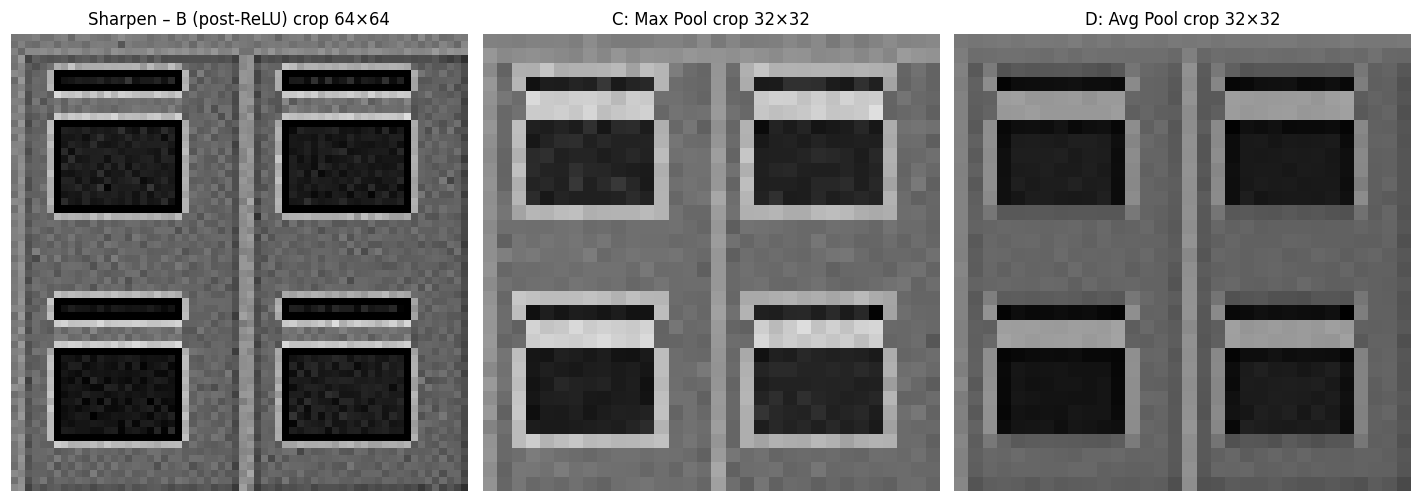

In [12]:
rows = []
for nm in (H_name, V_name, "Sharpen"):
    B, Cm, D = stages[nm]["B"], stages[nm]["C"], stages[nm]["D"]
    rows.append({"Filter": nm,
                 "Stage B max": B.max(),
                 "Stage C (MaxPool) max": Cm.max(), "Stage D (AvgPool) max": D.max(),
                 "AvgPool peak as % of MaxPool peak": 100 * D.max() / Cm.max(),
                 "Mean C": Cm.mean(), "Mean D": D.mean(),
                 "Std (contrast) C": Cm.std(), "Std (contrast) D": D.std(),
                 "% pixels above 50% of B-max: C": 100 * (Cm > 0.5 * B.max()).mean(),
                 "% pixels above 50% of B-max: D": 100 * (D > 0.5 * B.max()).mean()})
display(pd.DataFrame(rows).round(3).set_index("Filter").T)

# Zoom on a crop: B vs C vs D (same intensity scale)
nm = "Sharpen"; s = stages[nm]
fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
crop = (slice(0, 64), slice(0, 64)); crop_p = (slice(0, 32), slice(0, 32))
vmax = s["B"].max()
ax[0].imshow(s["B"][crop], cmap="gray", vmin=0, vmax=vmax);  ax[0].set_title("Sharpen – B (post-ReLU) crop 64×64")
ax[1].imshow(s["C"][crop_p], cmap="gray", vmin=0, vmax=vmax); ax[1].set_title("C: Max Pool crop 32×32")
ax[2].imshow(s["D"][crop_p], cmap="gray", vmin=0, vmax=vmax); ax[2].set_title("D: Avg Pool crop 32×32")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

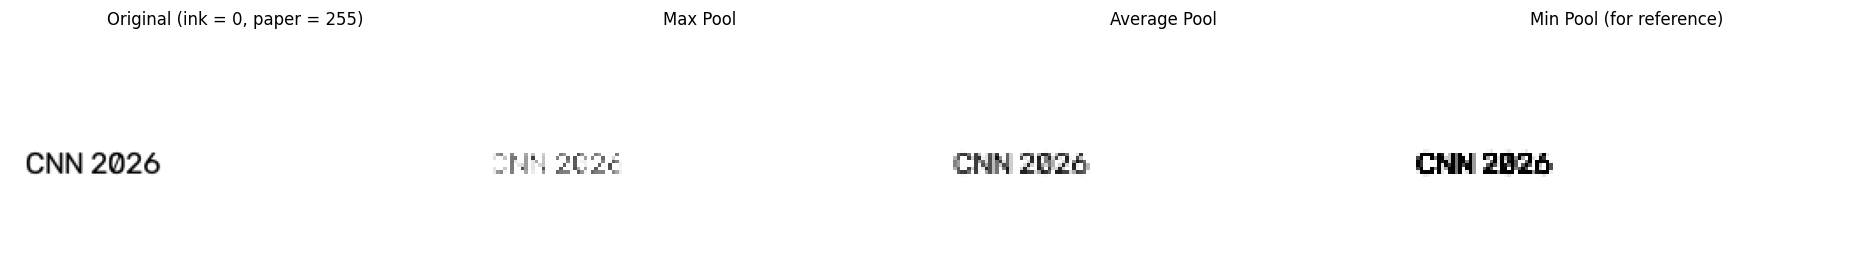

Ink amount per pixel  Original : 1.041 %
Ink amount per pixel  Max Pool : 0.433 %   -> 58 % of the ink is LOST (255 always wins)
Ink amount per pixel  Avg Pool : 1.041 %   -> 0 % lost (strokes survive, only blurred to grey)
Pixels darker than white  Original / Max / Avg : 1.79 % / 1.20 % / 2.47 %

2x2 patch with ONE ink pixel: max = 255, mean = 191.25


In [13]:
# Dark ink text on a pure white background (255)
canvas = np.full((128, 256), 255, np.uint8)
cv2.putText(canvas, "CNN 2026", (8, 80), cv2.FONT_HERSHEY_SIMPLEX, 0.6, 0, 1, cv2.LINE_8)   # thin 1-px black strokes
t = canvas.astype(np.float32)
mx, av = pool2x2(t, "max"), pool2x2(t, "avg")
mn = -pool2x2(-t, "max")

fig, ax = plt.subplots(1, 4, figsize=(17, 3.2))
for a, im_, ttl in zip(ax, (t, mx, av, mn), ("Original (ink = 0, paper = 255)", "Max Pool", "Average Pool", "Min Pool (for reference)")):
    a.imshow(im_, cmap="gray", vmin=0, vmax=255); a.set_title(ttl); a.axis("off")
plt.tight_layout(); plt.show()

mass = lambda x: (255 - x).mean() / 255 * 100        # average "ink darkness" per pixel, in %
print(f"Ink amount per pixel  Original : {mass(t):.3f} %")
print(f"Ink amount per pixel  Max Pool : {mass(mx):.3f} %   -> {100*(1-mass(mx)/mass(t)):.0f} % of the ink is LOST (255 always wins)")
print(f"Ink amount per pixel  Avg Pool : {mass(av):.3f} %   -> {100*(1-mass(av)/mass(t)):.0f} % lost (strokes survive, only blurred to grey)")
print(f"Pixels darker than white  Original / Max / Avg : {(t<255).mean()*100:.2f} % / {(mx<255).mean()*100:.2f} % / {(av<255).mean()*100:.2f} %")
patch = np.array([[255, 255], [255, 0]])
print(f"\n2x2 patch with ONE ink pixel: max = {patch.max()}, mean = {patch.mean():.2f}")

**Answer 2**

*Preserved by Max Pooling, washed out by Average Pooling.* In the Sharpen and Edge rows, the important information is **sparse, bright, high-frequency peaks** (thin strong edges, sharpened corners). A 2×2 window containing one strong edge pixel and three near-zero pixels gives:
* **Max Pool → the full peak value** (the edge keeps its strength; the table shows Stage C's peak equals Stage B's peak and has higher std/contrast),
* **Average Pool → as low as peak ÷ 4 (it averages in the neighbouring zeros)** — the edge is diluted into a dimmer, smoother blob (lower peak, lower std in the table, fewer pixels above 50 % of the maximum).
So Max Pooling keeps "*is the feature present anywhere in this window?*" while Average Pooling keeps "*how much of the feature is there on average?*" and low-pass-filters thin edges.

*Dark ink text on white (≈255):* **Average Pooling** preserves the strokes better. Max Pooling selects the largest value in each window, and the white paper (255) always beats the ink (≈0), so a thin stroke that does not fill an entire 2×2 window **disappears** (strokes only survive where ink fills a whole 2×2 block) (see the experiment above: Max Pool throws away most of the ink, while Average Pool keeps all of it because the mean of each window still contains the dark pixel). Average Pooling lets the dark pixels pull the window value down (e.g. one ink pixel in a window → 191), so the stroke stays visible, only softer. (Min Pooling, or inverting the image so ink becomes the bright signal before Max Pooling, would be the best of all — Max Pooling is only good when the *signal is bright*.)

### Question 3 — Parameter Explosion & Receptive Field Equivalence

In [14]:
inc = (manual_B - manual_A) / manual_A * 100
print(f"Model A = {manual_A}   Model B = {manual_B}")
print(f"Increase = ({manual_B} - {manual_A}) / {manual_A} x 100 = {inc:.2f} %   (x{manual_B/manual_A:.3f})\n")

# Receptive field of stacked 3x3 convs (stride 1): RF = 1 + 2n
for n in (1, 2, 3):
    print(f"{n} stacked 3x3 layer(s) -> receptive field {1+2*n}x{1+2*n}")
print("=> two 3x3 layers give exactly a 5x5 receptive field\n")

# (a) General case, C channels in and out
print("General case (C in = C out = C):   5x5: 25C^2 (+C bias)   vs   two 3x3: 18C^2 (+2C bias)")
print(f"   weight saving = 1 - 18/25 = {100*(1-18/25):.0f} %\n")

# (b) Exact numbers for THIS lab: replace every 5x5 conv of Model B by two stacked 3x3 convs
def stacked_pair(cin, cout):  return conv_params(3, cin, cout) + conv_params(3, cout, cout)
c1_5, c2_5 = conv_params(5, 3, 5), conv_params(5, 5, 10)
c1_33, c2_33 = stacked_pair(3, 5), stacked_pair(5, 10)
print("Per layer (this lab):")
print(f"   Conv1  3->5 : 5x5 = {c1_5}  | 3x3+3x3 = {c1_33}  -> saves {c1_5-c1_33}")
print(f"   Conv2  5->10: 5x5 = {c2_5} | 3x3+3x3 = {c2_33} -> saves {c2_5-c2_33}  (negative = costs more)")
tot_33 = c1_33 + c2_33 + dense_params(10, 10)
print(f"   Whole network: Model B = {manual_B} vs stacked-3x3 version = {tot_33}  -> saves {manual_B-tot_33}")

# Same-channel example where the saving is clean
c = 10
print(f"\nExample with C=10 in/out: 5x5 = {conv_params(5,c,c)} params, two 3x3 = {stacked_pair(c,c)} params -> saves {conv_params(5,c,c)-stacked_pair(c,c)} ({100*(conv_params(5,c,c)-stacked_pair(c,c))/conv_params(5,c,c):.1f} %)")

Model A = 710   Model B = 1750
Increase = (1750 - 710) / 710 x 100 = 146.48 %   (x2.465)

1 stacked 3x3 layer(s) -> receptive field 3x3
2 stacked 3x3 layer(s) -> receptive field 5x5
3 stacked 3x3 layer(s) -> receptive field 7x7
=> two 3x3 layers give exactly a 5x5 receptive field

General case (C in = C out = C):   5x5: 25C^2 (+C bias)   vs   two 3x3: 18C^2 (+2C bias)
   weight saving = 1 - 18/25 = 28 %

Per layer (this lab):
   Conv1  3->5 : 5x5 = 380  | 3x3+3x3 = 370  -> saves 10
   Conv2  5->10: 5x5 = 1260 | 3x3+3x3 = 1370 -> saves -110  (negative = costs more)
   Whole network: Model B = 1750 vs stacked-3x3 version = 1850  -> saves -100

Example with C=10 in/out: 5x5 = 2510 params, two 3x3 = 1820 params -> saves 690 (27.5 %)


**Answer 3**

*Increase:* Model A has **710** parameters, Model B has **1,750** → increase = (1750 − 710)/710 × 100 = **146.48 %** (≈ 2.46×). Pooling, ReLU and GAP add nothing; only the kernel area grows from 9 to 25 (×2.78) in the two conv layers, and the 110 Dense parameters stay fixed.

*Receptive field:* each extra stride-1 3×3 layer adds 2 pixels: RF = 1 + 2n. For a 5×5 field **n = 2 stacked 3×3 layers** are needed.

*Savings:* with C input and C output channels a 5×5 layer needs 25C² weights while two 3×3 layers need 2×9C² = 18C², i.e. **28 % fewer weights** (e.g. C = 10 → 2,510 vs 1,820 params, saves ≈ 27 % including biases), **and** you get an extra non-linearity (ReLU in between) and more expressive power.
In *this specific lab* the channel counts are small and unequal (3→5→10), so the extra intermediate layer partly cancels the saving: Conv1 saves 10 parameters, Conv2 actually needs 110 more (the second 3×3 layer has to map 10→10 channels). The 28 % rule is the asymptotic result for equal, large channel counts — a good point to mention in the viva.

### Question 4 — Operation Commutativity (Order Invariance)

In [15]:
# 1) Hand-sized 2x2 patch containing negative numbers
patch = np.array([[-3.0, 2.0],
                  [-1.0, 4.0]])
a = relu(patch).max()      # Conv -> ReLU -> MaxPool
b = relu(patch.max())      # Conv -> MaxPool -> ReLU
print("patch =\n", patch)
print(f"ReLU then MaxPool : max(relu(-3), relu(2), relu(-1), relu(4)) = max(0, 2, 0, 4) = {a}")
print(f"MaxPool then ReLU : relu(max(-3, 2, -1, 4)) = relu(4) = {b}")

# all-negative patch (the interesting corner case)
neg = np.array([[-3.0, -2.0], [-1.0, -5.0]])
print(f"\nAll-negative patch: ReLU->Max = {relu(neg).max()},  Max->ReLU = {relu(neg.max())}  (both 0)")

# 2) Verify on the real feature maps (all 5 filters)
for nm, s in stages.items():
    order1 = pool2x2(relu(s["A"]), "max")
    order2 = relu(pool2x2(s["A"], "max"))
    print(f"{nm:26s} identical? {np.array_equal(order1, order2)}   max |diff| = {np.abs(order1-order2).max():.1e}")

# 3) Same test with AVERAGE pooling -> NOT commutative
print()
for nm in (H_name, V_name):
    A = stages[nm]["A"]
    d = np.abs(pool2x2(relu(A), "avg") - relu(pool2x2(A, "avg")))
    print(f"AvgPool version, {nm:24s}: max |diff| = {d.max():.4f}  (differs)")

# 4) Efficiency: number of ReLU evaluations
H, W = stages[H_name]["A"].shape
print(f"\nReLU evaluations  Conv->ReLU->Pool : {H*W:,}")
print(f"ReLU evaluations  Conv->Pool->ReLU : {(H//2)*(W//2):,}   (4x fewer)")

patch =
 [[-3.  2.]
 [-1.  4.]]
ReLU then MaxPool : max(relu(-3), relu(2), relu(-1), relu(4)) = max(0, 2, 0, 4) = 4.0
MaxPool then ReLU : relu(max(-3, 2, -1, 4)) = relu(4) = 4.0

All-negative patch: ReLU->Max = 0.0,  Max->ReLU = 0.0  (both 0)
Horizontal Edge (Sobel)    identical? True   max |diff| = 0.0e+00
Vertical Edge (Sobel)      identical? True   max |diff| = 0.0e+00
Sharpen                    identical? True   max |diff| = 0.0e+00
Gaussian Blur              identical? True   max |diff| = 0.0e+00
Emboss                     identical? True   max |diff| = 0.0e+00

AvgPool version, Horizontal Edge (Sobel) : max |diff| = 0.0775  (differs)
AvgPool version, Vertical Edge (Sobel)   : max |diff| = 0.6402  (differs)

ReLU evaluations  Conv->ReLU->Pool : 65,536
ReLU evaluations  Conv->Pool->ReLU : 16,384   (4x fewer)


**Answer 4**

The output tensors are **identical** (for Max Pooling).

*Proof.* ReLU is a **monotonically non-decreasing** function, so it preserves ordering: for any numbers x₁ … x₄, `ReLU(max(x₁,…,x₄)) = max(ReLU(x₁),…,ReLU(x₄))`.
Take the patch `[[-3, 2], [-1, 4]]`:
* Conv → ReLU → MaxPool: ReLU gives `[[0, 2], [0, 4]]`, max = **4**.
* Conv → MaxPool → ReLU: max(−3, 2, −1, 4) = 4, ReLU(4) = **4**.
For an all-negative patch `[[-3,-2],[-1,-5]]`: first order → ReLU → all 0 → max = 0; second order → max = −1 → ReLU(−1) = **0**. Same again. The notebook also confirmed `np.array_equal` = True on all five real feature maps.

*Efficiency:* with the second order, Max Pool runs first and shrinks the map by 4× (H×W → H/2×W/2), so ReLU is evaluated on **4× fewer elements** (65,536 → 16,384 for a 256×256 map). The result is the same, so the reordering is free speed-up.
*Caveat:* this equivalence holds for **Max Pooling only**. For Average Pooling the order matters (ReLU is non-linear, so `mean(ReLU(x)) ≠ ReLU(mean(x))` — the code above shows non-zero differences).

### Question 5 — Diagnosing Filter Redundancy (Debugging Scenario)
**Evidence:** a small NumPy demonstration that identical filters ⇒ identical feature maps ⇒ identical gradients (they can never diversify), and that He-initialised filters are diverse.

In [16]:
def cos_sim_matrix(filters):
    f = filters.reshape(filters.shape[0], -1)
    f = f / (np.linalg.norm(f, axis=1, keepdims=True) + 1e-12)
    return f @ f.T

rng = np.random.default_rng(0)
n_f = 5
const_init = np.ones((n_f, 3, 3), np.float32) * 0.1                      # root cause 1: identical/constant init
he_init    = rng.normal(0, np.sqrt(2 / 9), (n_f, 3, 3)).astype(np.float32)  # He-normal init

for nm, w in (("Constant (identical) init", const_init), ("He-normal random init", he_init)):
    S = cos_sim_matrix(w)
    off = S[~np.eye(n_f, dtype=bool)]
    maps = np.stack([conv2d(img, f) for f in w])
    map_corr = np.corrcoef(maps.reshape(n_f, -1))[~np.eye(n_f, dtype=bool)]
    print(f"{nm:28s} mean off-diagonal filter cosine sim = {off.mean():+.3f} | mean feature-map correlation = {map_corr.mean():+.3f}")

# Root cause 2: dead ReLUs from a huge learning-rate step (large negative bias)
w = he_init[0]; z = conv2d(img, w)
for bias in (0.0, -5.0):
    print(f"bias = {bias:+.1f}:  % of ReLU outputs that are zero = {100*(relu(z+bias)==0).mean():.1f} %  ->",
          "gradient flows" if (relu(z+bias)>0).any() else "DEAD filter (gradient = 0 everywhere, cannot recover)")

Constant (identical) init    mean off-diagonal filter cosine sim = +1.000 | mean feature-map correlation = +1.000
He-normal random init        mean off-diagonal filter cosine sim = +0.056 | mean feature-map correlation = -0.141
bias = +0.0:  % of ReLU outputs that are zero = 0.0 %  -> gradient flows
bias = -5.0:  % of ReLU outputs that are zero = 100.0 %  -> DEAD filter (gradient = 0 everywhere, cannot recover)


**Answer 5**

All five filters giving the same maps after 20 epochs means the filters are **not learning different things** (filter collapse / redundancy). Two distinct causes:

| # | Root cause | Why it collapses filters | Concrete fix |
|---|---|---|---|
| 1 | **Poor weight initialization** — zeros, constants, or the same seed/values for every filter (symmetry problem) | Identical filters produce identical outputs, therefore receive **identical gradients** and are updated identically forever (cosine similarity = 1 in the demo above). Very small random weights also give vanishing gradients. | Use **random, scale-aware initialization**: He/Kaiming normal for ReLU (`kernel_initializer="he_normal"`), Glorot for tanh/sigmoid. Never initialize all filters equally. |
| 2 | **Learning rate too high → dead ReLUs** (or an extreme bias shift) | One large update pushes pre-activations negative for every input; ReLU outputs 0 and its gradient is 0, so the filter **stops learning** (dead, as in the bias = −5 demo). Dead filters all output zero maps, which look "identical". A too-*small* LR gives the opposite problem (filters barely move from init). | Lower / schedule the learning rate (e.g. 1e-3 with Adam + decay or warm-up), add **BatchNorm** before ReLU, and/or switch to **Leaky ReLU / ELU** so negative inputs still pass gradient. |

Additional measures worth mentioning in the viva: more diverse data / data augmentation, weight decay tuned correctly, orthogonal initialization or a filter-diversity regularizer, and checking the monitoring tools (print per-filter cosine similarity and % of dead activations each epoch).

## Summary of Results

In [17]:
summary = pd.DataFrame({
    "Item": ["Model A trainable params (manual = Keras)", "Model B trainable params (manual = Keras)",
             "Increase A → B", "Layers of 3×3 needed for a 5×5 receptive field",
             "Conv→ReLU→MaxPool equals Conv→MaxPool→ReLU?", "Saved figure"],
    "Result": [f"{manual_A} = {model_A.count_params()}", f"{manual_B} = {model_B.count_params()}",
               f"{inc:.2f} %", "2",
               "Yes (Max Pool); No (Avg Pool)", "cnn_feature_grid_5x4.png"]})
display(summary)

,Item,Result
0,Model A trainable params (manual = Keras),710 = 710
1,Model B trainable params (manual = Keras),1750 = 1750
2,Increase A → B,146.48 %
3,Layers of 3×3 needed for a 5×5 receptive field,2
4,Conv→ReLU→MaxPool equals Conv→MaxPool→ReLU?,Yes (Max Pool); No (Avg Pool)
5,Saved figure,cnn_feature_grid_5x4.png
